# Polymarket EDA

## Preamble

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import sqlite3

## Load data

In [3]:
# Open the database
con = sqlite3.connect("../polymarket-scraper/events.db")

In [4]:
# Read SQL db into DataFrame
df = pd.read_sql("SELECT * FROM events",con)

## Clean Data

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 297373 entries, 0 to 297372
Data columns (total 88 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   id                     297373 non-null  str    
 1   ticker                 297371 non-null  str    
 2   slug                   297373 non-null  str    
 3   title                  297373 non-null  str    
 4   description            296691 non-null  str    
 5   resolutionSource       281430 non-null  str    
 6   startDate              297348 non-null  str    
 7   creationDate           297282 non-null  str    
 8   endDate                297172 non-null  str    
 9   image                  297373 non-null  str    
 10  icon                   297373 non-null  str    
 11  active                 297373 non-null  int64  
 12  closed                 297373 non-null  int64  
 13  archived               297365 non-null  float64
 14  new                    297335 non-null  float64

In [6]:
# Set the correct type for boolean columns
boolean_columns = (
    "active",
    "closed",
    "archived",
    "new",
    "featured",
    "restricted",
    "commentsEnabled",
    "enableOrderBook",
    "negRisk",
    "cyom",
    "showAllOutcomes",
    "showMarketImages",
    "automaticallyResolved",
    "enableNegRisk",
    "automaticallyActive",
    "live",
    "ended",
    "estimateValue",
    "cantEstimate",
    "pendingDeployment",
    "deploying"
)

df[[*boolean_columns]] = df[[*boolean_columns]].astype('boolean')

In [7]:
# Parse the string JSON values
object_columns = (
    "markets",
    "tags",
    "eventCreators",
)

In [8]:
def parse_json(json_str : str) : 
    return json.loads(json_str) if isinstance(json_str,str) else np.nan
    
df[[*object_columns]] = df[[*object_columns]].map(parse_json)

In [9]:
df[[*object_columns]]

,markets,tags,eventCreators
0,"[{'id': '239826', 'question': 'NBA: Will the M...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
1,"[{'id': '239167', 'question': 'NFL: Will the F...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
2,"[{'id': '238885', 'question': '(In-Game Tradin...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
3,"[{'id': '245948', 'question': '2022 Norway Che...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
4,"[{'id': '239496', 'question': 'NBA: Will the H...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
...,...,...,...
297368,"[{'id': '255435', 'question': 'Trump $83.3m ve...","[{'id': '164', 'label': 'law', 'slug': 'law', ...",NaN
297369,"[{'id': '255440', 'question': 'Boeing whistleb...","[{'id': '846', 'label': 'Boeing', 'slug': 'boe...",NaN
297370,"[{'id': '255443', 'question': 'Will Arizona be...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
297371,"[{'id': '255447', 'question': 'Will Arizona be...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN


In [23]:
df.iloc[0]["markets"]

[{'id': '239826',
  'question': 'NBA: Will the Mavericks beat the Grizzlies by more than 5.5 points in their December 4 matchup?',
  'conditionId': '0x064d33e3f5703792aafa92bfb0ee10e08f461b1b34c02c1f02671892ede1609a',
  'slug': 'nba-will-the-mavericks-beat-the-grizzlies-by-more-than-5pt5-points-in-their-december-4-matchup',
  'resolutionSource': 'https://www.nba.com/games',
  'endDate': '2021-12-04T00:00:00Z',
  'category': 'Sports',
  'liquidity': '50.000009',
  'startDate': '2021-12-04T19:35:03.796Z',
  'fee': '20000000000000000',
  'image': 'https://polymarket-upload.s3.us-east-2.amazonaws.com/nba-will-the-mavericks-beat-the-grizzlies-by-more-than-55-points-in-their-december-4-matchup-aa2992d1-38df-404a-9190-49a909775014.png',
  'icon': 'https://polymarket-upload.s3.us-east-2.amazonaws.com/nba-will-the-mavericks-beat-the-grizzlies-by-more-than-55-points-in-their-december-4-matchup-aa2992d1-38df-404a-9190-49a909775014.png',
  'description': 'In the upcoming NBA game, scheduled for De

## Preliminary Analysis

### General statistics for interesting numerical columns

In [10]:
interesting_columns = (
    "liquidity",
    "volume",
    "openInterest",
    "volume24hr",
    "volume1wk",
    "volume1mo",
    "volume1yr",
    "commentCount",
)

### Addressing Hypothesis: Are a majority of high-volume markets related to Sports?
To answer this, let's look at the distribution of trading volume across the top categories.

/var/folders/dh/gg9g2sr55mldcldx8ws6c6qw0000gn/T/ipykernel_20731/3783119191.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=true_category_volume.values, y=true_category_volume.index, palette='magma')


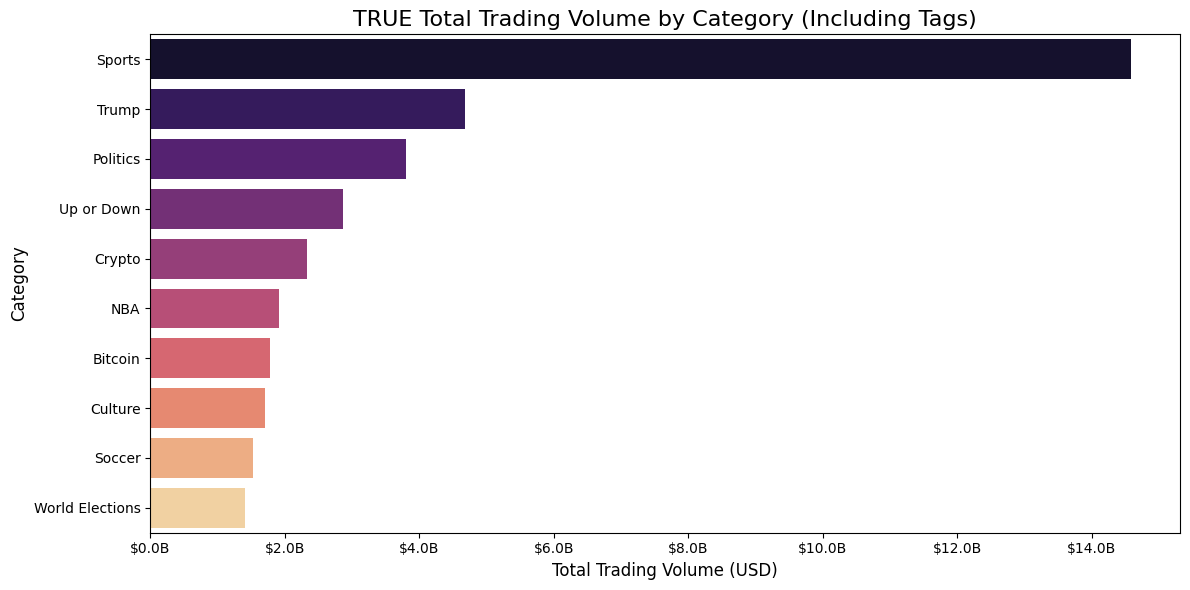

Top 10 True Categories by % of Total Volume:
primary_category
Sports             24.42%
Trump               7.83%
Politics            6.38%
Up or Down          4.81%
Crypto              3.91%
NBA                 3.20%
Bitcoin             2.98%
Culture             2.86%
Soccer              2.56%
World Elections     2.36%
Name: volume, dtype: object


In [ ]:
# extraction of the 'Primary Category' from the tags list
def extract_primary_category(row):
    # If the standard category exists, use it
    if pd.notna(row['category']) and row['category'] != '':
        return row['category']
    
    # Otherwise, parse the tags column if it's a valid list of dictionaries
    if isinstance(row['tags'], list) and len(row['tags']) > 0:
        # We can extract the label from the first tag 
        # (usually the broadest/most representative tag)
        return row['tags'][0].get('label', 'Unknown')
        
    return 'Unknown'

# Apply our custom extractor
df['primary_category'] = df.apply(extract_primary_category, axis=1)

# Now, recalculate the volume with our newly populated categories!
total_volume = df['volume'].sum()
true_category_volume = df.groupby('primary_category')['volume'].sum().sort_values(ascending=False).head(10)

# Plotting the adjusted data
plt.figure(figsize=(12, 6))
sns.barplot(x=true_category_volume.values, y=true_category_volume.index, palette='magma')
plt.title('TRUE Total Trading Volume by Category', fontsize=16)
plt.xlabel('Total Trading Volume (USD)', fontsize=12)
plt.ylabel('Category', fontsize=12)
formatter = ticker.FuncFormatter(lambda x, pos: f'${x*1e-9:,.1f}B') # Format to Billions now!
plt.gca().xaxis.set_major_formatter(formatter)
plt.tight_layout()
plt.show()

# Print the real percentages
print("Top 10 True Categories by % of Total Volume:")
print((true_category_volume / total_volume * 100).apply(lambda x: f"{x:.2f}%"))